# Ngô Minh Khôi - 6451071037
## Bai2 - Câu 6

Ngô Minh Khôi - 6451071037
--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH (min_sup = 3%) ---
1. Số tập phổ biến tìm được: Apriori = 131, FP-Growth = 131
2. Thời gian thực thi: Apriori = 3.2485s, FP-Growth = 4.9367s
Nhận xét: Cả hai thuật toán đều cho ra kết quả tập phổ biến chính xác như nhau, tuy nhiên FP-Growth tiết kiệm thời gian hơn do cấu trúc cây FP nén không phải sinh tập ứng viên.


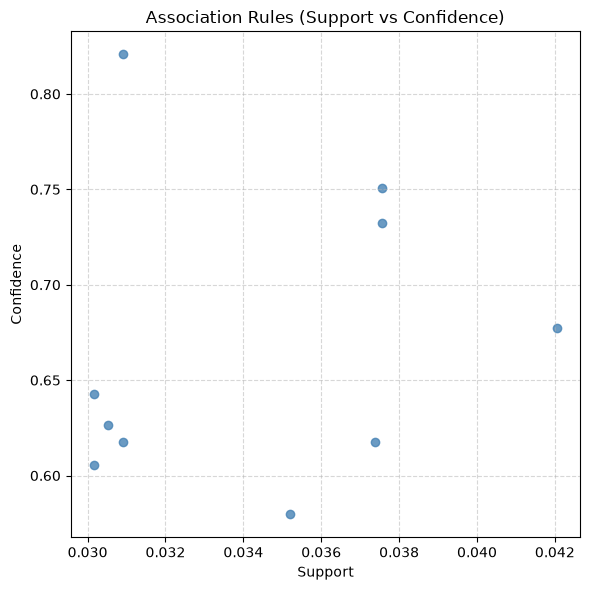

In [1]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 6: Biểu đồ scatter plot luật kết hợp & so sánh với FP-Growth
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == "United Kingdom"]
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket >= 1).astype(int)
if 'POSTAGE' in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=['POSTAGE'])

t0 = time.time()
frequent_itemsets_ap = apriori(basket_sets.astype(bool), min_support=0.03, use_colnames=True)
t_ap = time.time() - t0

t0 = time.time()
frequent_itemsets_fp = fpgrowth(basket_sets.astype(bool), min_support=0.03, use_colnames=True)
t_fp = time.time() - t0

rules = association_rules(frequent_itemsets_ap, metric="confidence", min_threshold=0.5)

plt.figure(figsize=(6, 6))
plt.title('Association Rules (Support vs Confidence)')
plt.xlabel('Support')
plt.ylabel('Confidence')
sns.regplot(x=rules['support'].values, y=rules['confidence'].values, fit_reg=False, color='steelblue')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(r"figures/p2_b2_t37_c6_rules.png", dpi=150)
plt.show()

print(f"--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH (min_sup = 3%) ---")
print(f"1. Số tập phổ biến tìm được: Apriori = {len(frequent_itemsets_ap)}, FP-Growth = {len(frequent_itemsets_fp)}")
print(f"2. Thời gian thực thi: Apriori = {t_ap:.4f}s, FP-Growth = {t_fp:.4f}s")
print(f"Nhận xét: Cả hai thuật toán đều cho ra kết quả tập phổ biến chính xác như nhau, tuy nhiên FP-Growth tiết kiệm thời gian hơn do cấu trúc cây FP nén không phải sinh tập ứng viên.")
